# 实验二：搜索算法

这次先完成四道题，再尝试改变启发函数、访问顺序和叶子评价。关注的重点是：答案怎样得到，哪些节点被省略，以及这种省略是否保持相同的搜索结果。所有注释和分析对应实际运行记录。

In [1]:
from pathlib import Path
import json
from dataclasses import asdict
import pandas as pd
from IPython.display import display, Image

from astar import astar_grid, solve_maze, solve_weighted, bfs_grid, astar_graph
from game_search import minimax, alpha_beta, tree_search
from treasure import TreasureGame, distance_matrix, solve_treasure
from cases import MAZE, WEIGHTED, TREASURE_MAP, TREASURE_VALUES, example_tree

ROOT = Path.cwd()
RESULTS = ROOT / 'results'
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.precision', 4)
def read_json(name):
    return json.loads((RESULTS / name).read_text(encoding='utf-8'))

## 1. 迷宫：先得到一条最短路径

题目一每次移动代价为 1，四个方向可选。A* 维护已知路径代价 g、剩余代价估计 h 和 f=g+h。取出候选中 f 最小的节点，发现更短路径就更新前驱，直到终点出队。

这里先直接调用解题接口，再与 BFS 的步数对照。

In [2]:
path = solve_maze((0, 0), (3, 4), MAZE)
print('路径：', path)
print('步数：', len(path) - 1)
print('BFS 代价：', bfs_grid((0, 0), (3, 4), MAZE).cost)
detail = astar_grid((0, 0), (3, 4), MAZE, trace=True)
display(pd.DataFrame(detail.trace))

路径： [(0, 0), (0, 1), (0, 2), (1, 2), (1, 3), (1, 4), (2, 4), (3, 4)]
步数： 7
BFS 代价： 7


,event,node,g,h,f
0,取出,"(0, 0)",0,7,7
1,取出,"(0, 1)",1,6,7
2,取出,"(0, 2)",2,5,7
3,取出,"(1, 2)",3,4,7
4,取出,"(1, 3)",4,3,7
5,取出,"(1, 4)",5,2,7
6,取出,"(2, 4)",6,1,7
7,取出,"(3, 4)",7,0,7


## 2. 加权地形：进入代价与终点免费

每次移动支付下一格的权值，起点初始代价为 0。E 的进入代价为 0，所以相邻格到 E 的实际剩余代价也是 0。普通曼哈顿距离在这里估计为 1，需要把免费的一步扣除。令 m 为其他格子的最小进入代价，采用 h=m·max(D−1,0)。

加权最小代价： 7


,step,row,col,entered_cost,cumulative
0,0,0,0,0.0,0.0
1,1,1,0,1.0,1.0
2,2,2,0,1.0,2.0
3,3,3,0,1.0,3.0
4,4,3,1,1.0,4.0
5,5,3,2,1.0,5.0
6,6,4,2,1.0,6.0
7,7,4,3,1.0,7.0
8,8,4,4,0.0,7.0


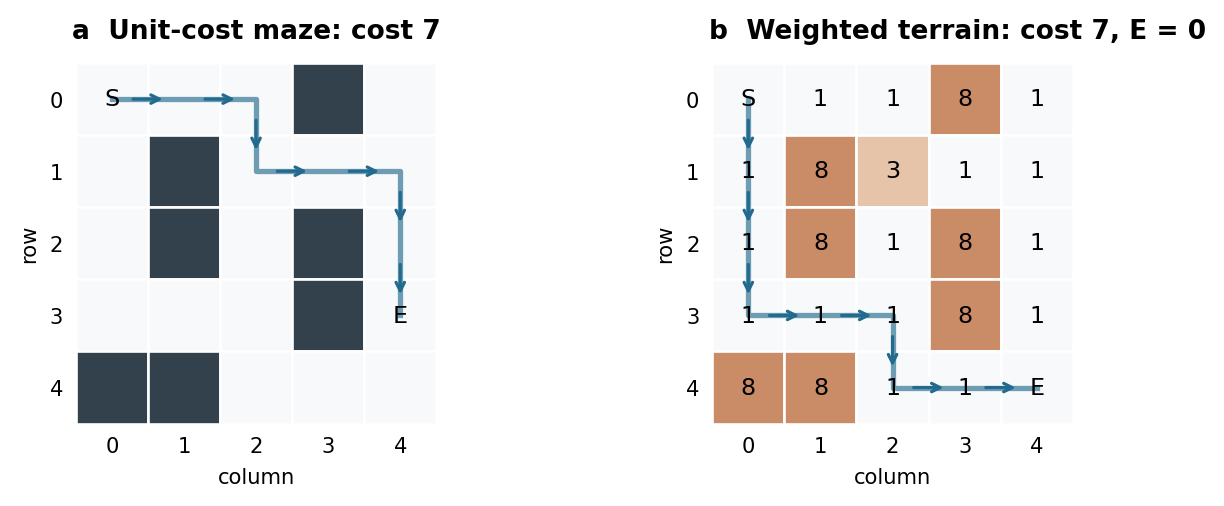

,task,heuristic,tie,cost,reachable,path_steps,expanded,pushed,popped,stale,reopened,peak_open,median_ms,iqr_ms,repeats
0,q1,zero,fifo,7.0,True,7,15,17,16,0,0,3,0.0323,0.0018,7
1,q1,manhattan,fifo,7.0,True,7,13,16,14,0,0,3,0.0415,0.0065,7
2,q1,safe,fifo,7.0,True,7,13,16,14,0,0,3,0.0340,0.0008,7
3,q1,safe,larger_g,7.0,True,7,7,11,8,0,0,4,0.0234,0.0007,7
4,q1,bfs,fifo,7.0,True,7,15,17,16,0,0,3,0.0195,0.0009,7
5,q2,zero,fifo,7.0,True,8,14,24,15,0,0,10,0.0438,0.0035,7
6,q2,manhattan,fifo,7.0,True,8,10,19,11,0,0,9,0.0357,0.0009,7
7,q2,safe,fifo,7.0,True,8,10,19,11,0,0,9,0.0410,0.0005,7
8,q2,safe,larger_g,7.0,True,8,10,19,11,0,0,9,0.0415,0.0018,7


In [3]:
print('加权最小代价：', solve_weighted((0, 0), (4, 4), WEIGHTED))
display(pd.read_csv(RESULTS / 'weighted_path.csv'))
display(Image(filename=str(RESULTS / 'figures/given_paths.png')))
display(pd.read_csv(RESULTS / 'given_paths.csv').drop(columns='time_samples_ms'))

可采纳性检查每个节点的 h 是否超过真实剩余最小代价；一致性检查每条边是否满足 h(n)≤c(n,n′)+h(n′)。以下数据由反向 Dijkstra 提供真实剩余代价。

In [4]:
audit = read_json('heuristic_audit.json')
display(pd.DataFrame([{key: row[key] for key in ['heuristic', 'admissibility_violations', 'consistency_violations']} for row in audit]))
display(pd.DataFrame(audit[1]['edges']))

,heuristic,admissibility_violations,consistency_violations
0,zero,0,0
1,manhattan,20,2
2,safe,0,0


,source,target,h_source,edge,h_target
0,"[3, 4]","[4, 4]",1,0,0
1,"[4, 3]","[4, 4]",1,0,0


## 3. 为什么保留重新打开节点

构造 S→A→G（代价 3+3）和 S→B→A→G（代价 1+1+3），令 h(A)=0、h(B)=4。估计可采纳，但 B→A 不满足一致性。A 会先以 g=3 关闭，随后经过 B 才发现 g=2。下面实际比较允许重开与永久关闭。

In [5]:
graph = {'S': [('A', 3), ('B', 1)], 'A': [('G', 3)], 'B': [('A', 1)], 'G': []}
h = {'S': 0, 'A': 0, 'B': 4, 'G': 0}
for reopen in [False, True]:
    answer = astar_graph('S', 'G', lambda n: graph[n], lambda n: h[n], reopen=reopen, trace=True)
    print('允许重开：', reopen, '路径：', answer.path, '代价：', answer.cost)
    display(pd.DataFrame(answer.trace))

允许重开： False 路径： ['S', 'A', 'G'] 代价： 6


,event,node,g,h,f
0,取出,S,0,0,0
1,取出,A,3,0,3
2,取出,B,1,4,5
3,取出,G,6,0,6


允许重开： True 路径： ['S', 'B', 'A', 'G'] 代价： 5


,event,node,g,h,f,old_g,new_g
0,取出,S,0.0,0.0,0.0,NaN,NaN
1,取出,A,3.0,0.0,3.0,NaN,NaN
2,取出,B,1.0,4.0,5.0,NaN,NaN
3,重开,A,NaN,NaN,NaN,3.0,2.0
4,取出,A,2.0,0.0,2.0,NaN,NaN
5,取出,G,5.0,0.0,5.0,NaN,NaN


## 4. 同一个 f，先看哪个节点

空地图的许多节点满足 f=2(N−1)。FIFO 会逐层处理同分节点，较大 g 优先则沿一条路线前进。先固定 FIFO 比较零启发与安全启发，再固定启发比较不同平局规则。不可达地图也一起保留，用于观察最坏情况和空间开销。

,name,heuristic,tie,reachable,cost,expanded,peak_open,median_ms
0,open_20,zero,fifo,True,38.0,399,20,0.8452
1,open_20,safe,fifo,True,38.0,399,20,1.0571
2,open_20,safe,larger_g,True,38.0,38,37,0.9232
3,open_20,safe,smaller_g,True,38.0,399,20,1.3461
4,obstacle_20_66,zero,fifo,True,38.0,309,19,0.6820
...,...,...,...,...,...,...,...,...
59,terrain_80_88,safe,smaller_g,True,204.0,3460,414,22.7471
60,blocked_20,zero,fifo,False,NaN,200,11,0.8967
61,blocked_20,safe,fifo,False,NaN,200,11,1.0862
62,blocked_20,safe,larger_g,False,NaN,200,153,1.4068


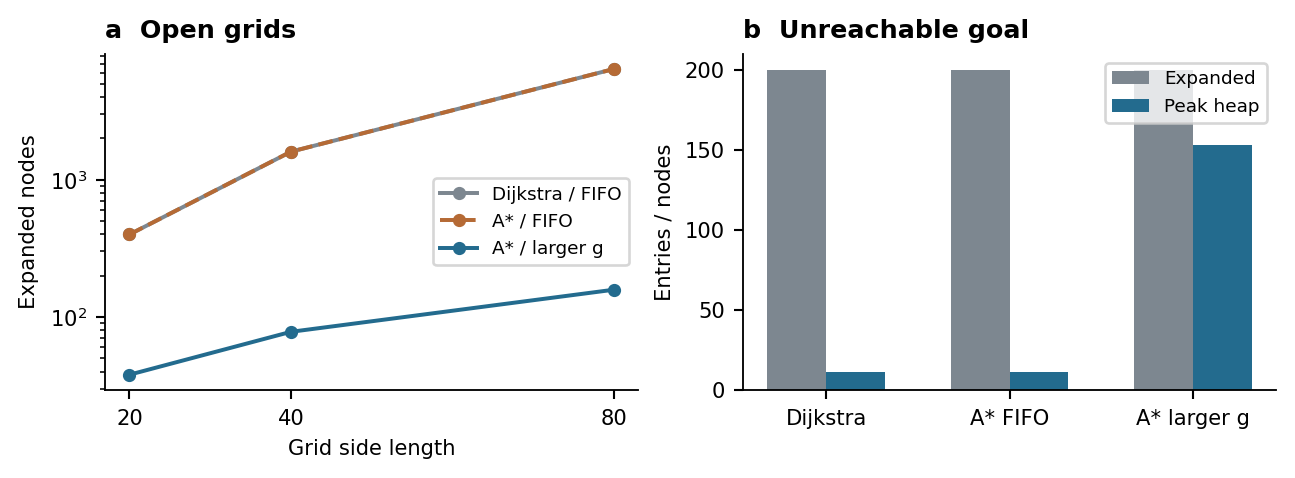

In [6]:
paths = pd.read_csv(RESULTS / 'path_benchmarks.csv')
display(paths[['name', 'heuristic', 'tie', 'reachable', 'cost', 'expanded', 'peak_open', 'median_ms']])
display(Image(filename=str(RESULTS / 'figures/path_scaling.png')))

## 5. 博弈树：从叶子回传到根

根节点为 MAX，下一层为 MIN，随后交替。Minimax 完整回传，Alpha-beta 在已有上下界足以确定父节点选择时跳过后续分支。课程构造中的 (6,9) 分支被到达两次，访问计数按两次发生分别累计。

Minimax： 5
Alpha-beta： 5


,algorithm,order,value,first,visited,leaves,cutoffs,skipped_children,median_ms,iqr_ms,repeats
0,minimax,natural,5,0,15,8,0,0,0.0222,0.0027,7
1,minimax,reverse,5,0,15,8,0,0,0.0220,0.0002,7
2,minimax,random,5,0,15,8,0,0,0.0872,0.0011,7
3,alpha_beta,natural,5,0,14,7,1,1,0.0226,0.0014,7
4,alpha_beta,reverse,5,0,14,7,1,1,0.0230,0.0006,7
5,alpha_beta,random,5,0,11,5,2,2,0.0723,0.0006,7


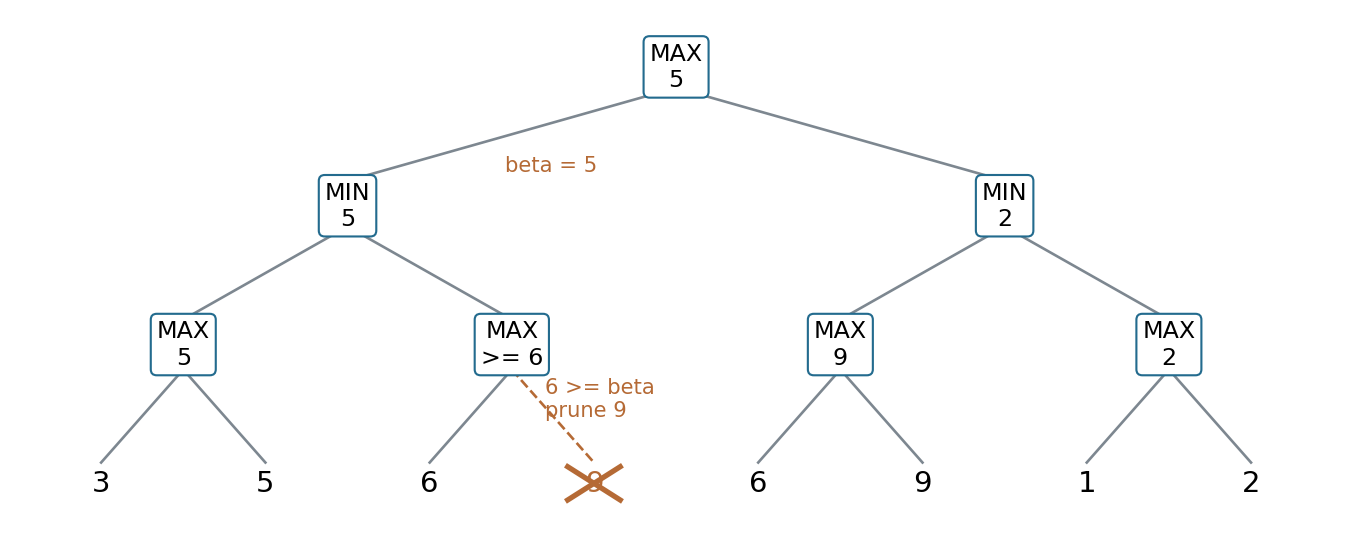

,event,path,value,alpha,beta,bound,alpha_in,beta_in,action,skipped
0,叶子,r/0/0/0,3.0,-inf,inf,NaN,NaN,NaN,NaN,NaN
1,叶子,r/0/0/1,5.0,3.0,inf,NaN,NaN,NaN,NaN,NaN
2,回传,r/0/0,5.0,NaN,NaN,精确值,-inf,inf,1,NaN
3,叶子,r/0/1/0,6.0,-inf,5.0,NaN,NaN,NaN,NaN,NaN
4,剪枝,r/0/1,NaN,6.0,5.0,NaN,NaN,NaN,NaN,[1]
5,回传,r/0/1,6.0,NaN,NaN,下界,-inf,5.0,0,NaN
6,回传,r/0,5.0,NaN,NaN,精确值,-inf,inf,0,NaN
7,叶子,r/1/0/0,6.0,5.0,inf,NaN,NaN,NaN,NaN,NaN
8,叶子,r/1/0/1,9.0,6.0,inf,NaN,NaN,NaN,NaN,NaN
9,回传,r/1/0,9.0,NaN,NaN,精确值,5.0,inf,1,NaN


In [7]:
tree = example_tree()
print('Minimax：', minimax(tree))
print('Alpha-beta：', alpha_beta(tree))
display(pd.read_csv(RESULTS / 'given_tree.csv').drop(columns='time_samples_ms'))
display(Image(filename=str(RESULTS / 'figures/tree_pruning.png')))
traced = tree_search(tree, trace=True)
display(pd.DataFrame(traced.events))

左侧 MIN 已得到 5，右侧 MAX 看到 6 后就可以剪去 9。此处返回的 6 是真实值的下界；完整展开会得到 9。报告将界与精确值分别标出，方便理解提前停止的依据。

继续改变访问顺序时，树结构与叶子分数保持相同。随机顺序由节点名和种子确定，生成顺序的开销也计入时间。

,seed,algorithm,order,value,visited,leaves,median_ms
24,66,minimax,natural,-7,1093,729,1.8193
25,66,minimax,reverse,-7,1093,729,1.9424
26,66,minimax,random,-7,1093,729,3.9649
27,66,alpha_beta,natural,-7,390,224,0.5459
28,66,alpha_beta,reverse,-7,500,281,0.5088
29,66,alpha_beta,random,-7,474,271,2.6496
60,88,minimax,natural,-5,1093,729,1.5222
61,88,minimax,reverse,-5,1093,729,1.9241
62,88,minimax,random,-5,1093,729,6.9442
63,88,alpha_beta,natural,-5,614,351,1.5262


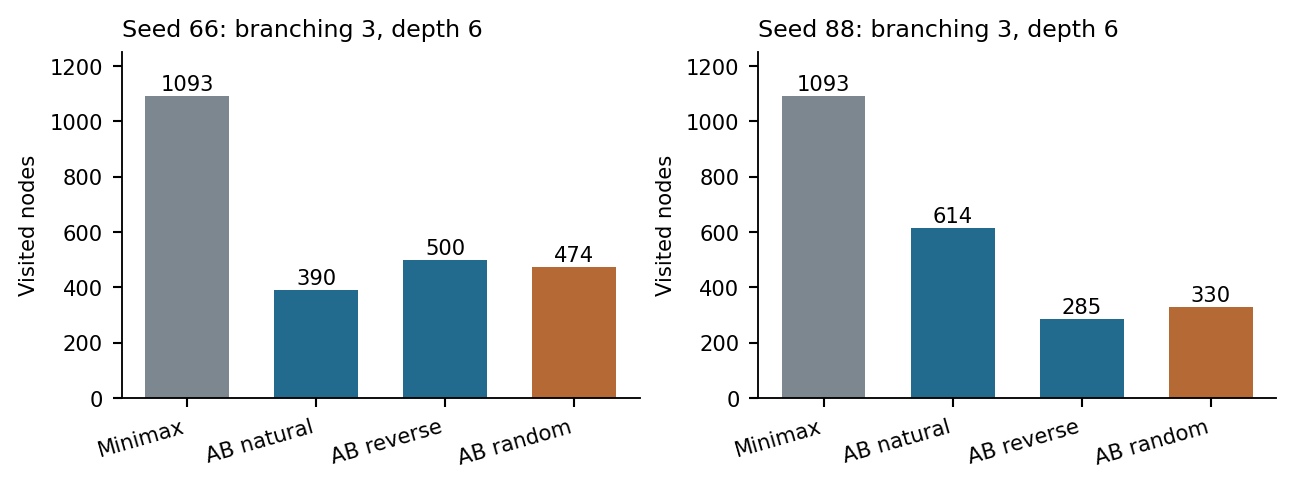

In [8]:
trees = pd.read_csv(RESULTS / 'tree_benchmarks.csv')
display(trees[(trees.branching == 3) & (trees.depth == 6)][['seed', 'algorithm', 'order', 'value', 'visited', 'leaves', 'median_ms']])
display(Image(filename=str(RESULTS / 'figures/tree_order.png')))

## 6. 宝藏题：把寻路结果放进博弈状态

状态包含双方位置、剩余宝藏、双方累计收益与当前玩家。A、B 和宝藏格代价都是 1。每回合只获得选中的宝藏，然后从新位置继续；负收益仍按规则计入。

先实际计算 30 个有向位置对的距离，再分别求两层和四层的行动。

In [9]:
names, distances, details = distance_matrix(TREASURE_MAP)
display(pd.DataFrame(distances).T.loc[names, names])
game = TreasureGame(distances, TREASURE_VALUES)
for depth in [2, 4]:
    answer = game.solve(depth)
    print('H =', depth, '首步：', answer.best_action, '收益差：', answer.value)
    display(pd.DataFrame(game.trajectory(answer.principal_variation)))
display(pd.read_csv(RESULTS / 'root_values.csv'))

,A,B,T1,T2,T3,T4
A,0.0,12.0,10.0,4.0,8.0,8.0
B,12.0,0.0,8.0,8.0,4.0,10.0
T1,10.0,8.0,0.0,6.0,6.0,12.0
T2,4.0,8.0,6.0,0.0,6.0,6.0
T3,8.0,4.0,6.0,6.0,0.0,6.0
T4,8.0,10.0,12.0,6.0,6.0,0.0


H = 2 首步： T2 收益差： -1.0


,turn,player,source,target,distance,gain,score_a,score_b,utility
0,1,A,A,T2,4.0,2.0,2.0,0.0,2.0
1,2,B,B,T3,4.0,3.0,2.0,3.0,-1.0


H = 4 首步： T3 收益差： 3.0


,turn,player,source,target,distance,gain,score_a,score_b,utility
0,1,A,A,T3,8.0,-1.0,-1.0,0.0,-1.0
1,2,B,B,T1,8.0,1.0,-1.0,1.0,-2.0
2,3,A,T3,T2,6.0,0.0,-1.0,1.0,-2.0
3,4,B,T1,T4,12.0,-5.0,-1.0,-4.0,3.0


,depth,target,value,terminal_value
0,2,T1,-4.0,-5.0
1,2,T2,-1.0,1.0
2,2,T3,-2.0,3.0
3,2,T4,-4.0,-7.0
4,4,T1,-5.0,-5.0
5,4,T2,1.0,1.0
6,4,T3,3.0,3.0
7,4,T4,-7.0,-7.0


H=2 只看两次行动后的收益差；H=4 看四次行动后的终局收益。固定浅层选出的 T2 首步并补满四回合，得到 1；完整搜索的 T3 首步得到 3，实际终局差距为 2。

下面比较相同深度下的访问开销。收益排序按当前玩家即时收益从高到低排列，A 优先增加 U，B 优先减小 U。

In [10]:
display(pd.read_csv(RESULTS / 'given_treasure.csv').drop(columns='time_samples_ms'))
state = game.step(game.initial, 'T2')
print('A 取 T2 后：', state)
state = game.step(state, 'T3')
print('B 取 T3 后：', state)

,depth,algorithm,order,value,first,visited,leaves,cutoffs,skipped_children,median_ms,iqr_ms,repeats
0,2,minimax,natural,-1.0,T2,17,12,0,0,0.0431,0.0024,7
1,2,minimax,reverse,-1.0,T2,17,12,0,0,0.0412,0.0004,7
2,2,minimax,gain,-1.0,T2,17,12,0,0,0.0483,0.0179,7
3,2,alpha_beta,natural,-1.0,T2,13,8,2,4,0.0334,0.0004,7
4,2,alpha_beta,reverse,-1.0,T2,16,11,1,1,0.0408,0.0006,7
5,2,alpha_beta,gain,-1.0,T2,11,6,3,6,0.0346,0.0021,7
6,4,minimax,natural,3.0,T3,65,24,0,0,0.1507,0.0165,7
7,4,minimax,reverse,3.0,T3,65,24,0,0,0.1531,0.0126,7
8,4,minimax,gain,3.0,T3,65,24,0,0,0.1650,0.0080,7
9,4,alpha_beta,natural,3.0,T3,47,16,5,6,0.1124,0.0009,7


A 取 T2 后： State(pos_a='T2', pos_b='B', remaining=('T1', 'T3', 'T4'), score_a=2.0, score_b=0, player='B')
B 取 T3 后： State(pos_a='T2', pos_b='T3', remaining=('T1', 'T4'), score_a=2.0, score_b=3.0, player='A')


## 7. 浅层搜索能否估计剩余机会

尝试在截止叶子的当前收益差上，加上“A 的最佳剩余即时收益减 B 的最佳剩余即时收益”，系数固定为 1。该估计按双方当前位置查距离矩阵。20 张自设地图在运行前按固定规则生成；只根据连通性接受或剔除候选。

每种方法选出首步后，再用完整搜索求后续最优应对。首步损失等于完整最优收益减去该首步的终局收益；损失为 0 时视为命中最优行动。这个核验计算与在线选择首步的计时分开。

,method,first,value,terminal_value,regret,visited,median_ms
0,H2_current,T2,-1.0,1.0,2.0,13.0,0.0691
1,H2_opportunity,T2,-1.0,1.0,2.0,13.0,0.0887
2,H4_full,T3,3.0,3.0,0.0,47.0,0.2253
3,greedy,T2,2.0,1.0,2.0,NaN,0.0024


,seed,method,cases,optimal_first_rate,mean_regret,max_regret,mean_visited,median_ms
0,66.0,H2_current,10,0.7,1.9,8.0,14.6,0.0725
1,66.0,H2_opportunity,10,0.9,0.2,2.0,14.7,0.0983
2,66.0,H4_full,10,1.0,0.0,0.0,53.3,0.2816
3,66.0,greedy,10,0.4,4.2,14.0,NaN,0.0024
4,88.0,H2_current,10,0.8,0.6,3.0,14.1,0.0387
5,88.0,H2_opportunity,10,0.8,0.4,3.0,14.6,0.0514
6,88.0,H4_full,10,1.0,0.0,0.0,50.0,0.1249
7,88.0,greedy,10,0.7,2.2,11.0,NaN,0.0014


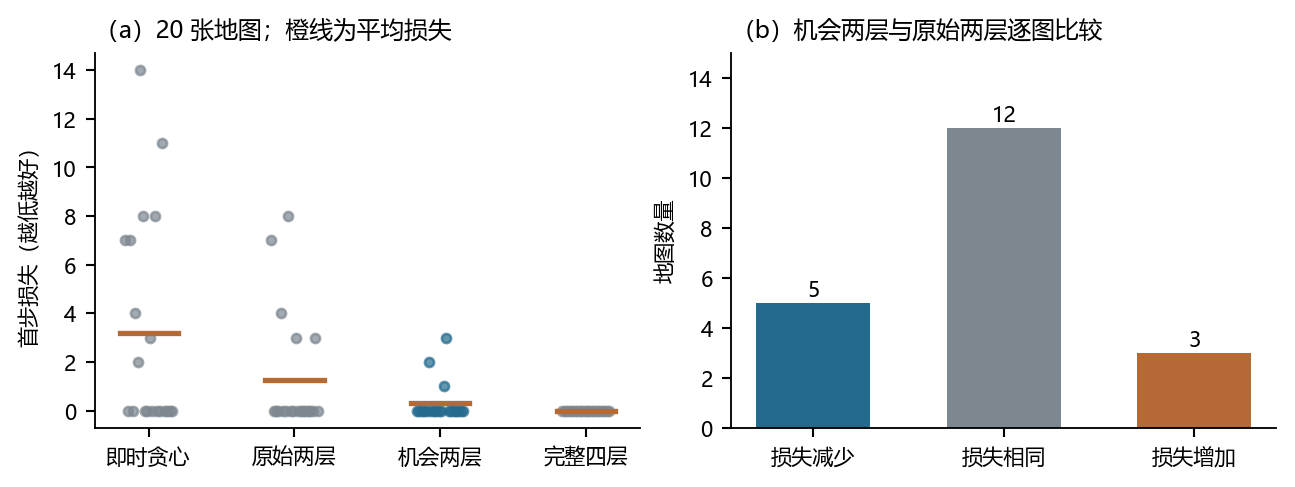

In [11]:
decisions = pd.read_csv(RESULTS / 'decision_benchmarks.csv')
display(decisions[decisions.name == 'given'][['method', 'first', 'value', 'terminal_value', 'regret', 'visited', 'median_ms']])
display(pd.read_csv(RESULTS / 'decision_summary.csv'))
display(Image(filename=str(RESULTS / 'figures/decision_quality.png')))

在给定图上，两种浅层评价仍都选 T2。自设图中，机会评价改善 5 次、变差 3 次、持平 12 次。下面保留一个改善明显的场景和一个失败场景，查看首步估值及完整行动序列。

In [12]:
examples = read_json('decision_examples.json')
for example in examples:
    if example['name'] in ['random_66_7', 'random_88_2']:
        print('场景：', example['name'], '宝藏价值：', example['values'])
        display(pd.DataFrame(example['roots']))
        print('当前收益评价选：', example['current_first'])
        display(pd.DataFrame(example['current_trajectory']))
        print('机会评价选：', example['opportunity_first'])
        display(pd.DataFrame(example['opportunity_trajectory']))

场景： random_66_7 宝藏价值： {'T1': 8, 'T2': 8, 'T3': 10, 'T4': 12}


,target,immediate_gain,current_h2,opportunity_h2,full_h4
0,T1,-6.0,-11.0,-21.0,-20.0
1,T2,4.0,-1.0,-7.0,3.0
2,T3,-3.0,-2.0,3.0,11.0
3,T4,-4.0,-9.0,-14.0,-9.0


当前收益评价选： T2


,turn,player,source,target,distance,gain,score_a,score_b,utility
0,1,A,A,T2,4.0,4.0,4.0,0.0,4.0
1,2,B,B,T3,5.0,5.0,4.0,5.0,-1.0
2,3,A,T2,T4,14.0,-2.0,2.0,5.0,-3.0
3,4,B,T3,T1,14.0,-6.0,2.0,-1.0,3.0


机会评价选： T3


,turn,player,source,target,distance,gain,score_a,score_b,utility
0,1,A,A,T3,13.0,-3.0,-3.0,0.0,-3.0
1,2,B,B,T4,13.0,-1.0,-3.0,-1.0,-2.0
2,3,A,T3,T2,9.0,-1.0,-4.0,-1.0,-3.0
3,4,B,T4,T1,22.0,-14.0,-4.0,-15.0,11.0


... (2 outputs left out)

当前收益评价选： T3


,turn,player,source,target,distance,gain,score_a,score_b,utility
0,1,A,A,T3,18.0,-7.0,-7.0,0.0,-7.0
1,2,B,B,T4,11.0,1.0,-7.0,1.0,-8.0
2,3,A,T3,T2,9.0,-3.0,-10.0,1.0,-11.0
3,4,B,T4,T1,19.0,-9.0,-10.0,-8.0,-2.0


机会评价选： T2


,turn,player,source,target,distance,gain,score_a,score_b,utility
0,1,A,A,T2,9.0,-3.0,-3.0,0.0,-3.0
1,2,B,B,T3,5.0,6.0,-3.0,6.0,-9.0
2,3,A,T2,T4,7.0,5.0,2.0,6.0,-4.0
3,4,B,T3,T1,9.0,1.0,2.0,7.0,-5.0


场景 66–7 中，机会评价把首步从 T2 改为 T3，终局收益从 3 提高到 11；后续 B 的长距离移动产生了明显负收益。场景 88–2 中，T2 与 T3 的机会估值都为 −6，固定顺序选了 T2，终局为 −5；选 T3 可得到 −2。并列估值使这两个行动的后续差别被压平。

这次实验中，同分排序、上下界和叶子评价分别影响搜索路径、搜索量与决策质量。后续可继续把剩余宝藏的竞争归属加入评价，尤其关注两个玩家同时看中同一目标的状态。

## 8. 复现与核对

在项目目录运行 `python experiments.py --plots`，可以重新生成全部实验结果与图片。每个计时配置先预热一次，再记录七次运行，CSV 保存中位数、四分位距和七个原始值。机器负载会影响耗时，路径代价、博弈值和节点计数应保持一致。

临时核对脚本在开发后清理，独立核对汇总与运行环境保存在下面的记录中。

In [13]:
display(read_json('validation.json'))
display({k: v for k, v in read_json('environment.json').items() if k != 'source_sha256'})
display(pd.DataFrame(read_json('generation_attempts.json')))

{'path_pairs': 1200,
 'heuristic_edges': 3756,
 'tree_comparisons': 180,
 'treasure_prefixes': 104,
 'treasure_scenarios': 20,
 'status': '通过'}

{'python': '3.11.7',
 'platform': 'Windows-10-10.0.26200-SP0',
 'repeats': 7,
 'seeds': [66, 88],
 'wall_seconds': 4.786230199970305}

,seed,candidate,connected
0,66,0,True
1,66,1,True
2,66,2,True
3,66,3,True
4,66,4,True
5,66,5,True
6,66,6,False
7,66,7,True
8,66,8,True
9,66,9,True
